# ConectaMap — Notebook 2: modelagem preditiva e previsão para fevereiro de 2029
**Global Solution FIAP 2026.2 · CitizenTech**

## 1. Introdução e objetivo da modelagem
O Notebook 1 tratou as séries de densidade de banda larga fixa da Anatel (2007–2026) e os dados do Censo 2022. Este notebook usa essas bases para responder a uma pergunta de priorização:

> **Quais municípios brasileiros têm maior risco relativo de continuar com baixa densidade de banda larga fixa em fevereiro de 2029?**

| Elemento | Definição |
|---|---|
| Origem da previsão | fevereiro de 2026, o último mês observado |
| Horizonte | 36 meses, até **fevereiro de 2029** |
| Alvo | densidade publicada pela Anatel (`densidade_original`) abaixo do **P25 nacional congelado na origem**, que em fev/2026 é de **8,20 acessos por 100 domicílios** |
| Modelo | Random Forest com 30 features temporais da Anatel, em protocolo congelado |
| Referência principal | B2: ordenação pela densidade atual, com a menor densidade no topo |
| Resultado | **priorização relativa** dos 5.570 municípios |

**Como ler os resultados**
- A previsão **não é um fato observado**: o alvo de 2029 ainda não existe.
- O Random Forest **não demonstrou vantagem robusta** sobre a ordenação pela densidade atual.
- Os escores do modelo **não foram homologados como probabilidades calibradas**.
- O resultado final é uma **priorização relativa**, não uma estimativa de quantos municípios ficarão abaixo de 8,20.

**Reprodutibilidade**
- O notebook só **lê** as bases do Notebook 1.
- O modelo, as features e o protocolo de avaliação são os aprovados e não são alterados.
- O teste reservado (2023) foi avaliado uma única vez, numa etapa anterior; aqui os resultados dele só são lidos.
- A previsão é **recalculada e conferida byte a byte** com os arquivos aprovados, sem regravá-los.
- Tempo de execução: cerca de 2,5 minutos, incluindo os testes automáticos.

In [1]:
from pathlib import Path
import hashlib
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, str(Path(".").resolve()))
from conectamap import apresentacao as AP, painel as PN, previsao as PV, treino as TR

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 180)
SAIDAS = Path("etapa2") / "saidas"
TREINO, PREVISAO, FIGURAS = SAIDAS / "treino", SAIDAS / "previsao2029", SAIDAS / "figuras"
FIGURAS.mkdir(exist_ok=True)
RODAR_SELECAO_COMPLETA = False   # True refaz a seleção de modelos (≈4 min) e confere o vencedor com o protocolo congelado

# arquivos aprovados que este notebook NÃO pode alterar (conferidos de novo no fim)
PROTEGIDOS = sorted([Path("ConectaMap_Pre_Processamento.ipynb"), Path("etapa2/protocolo_treino_congelado.json"),
                     *Path("dados_brutos").glob("*"), *Path("dados_tratados").glob("*"),
                     *[p for p in SAIDAS.glob("*") if p.is_file()], *TREINO.glob("*"),
                     *[p for p in PREVISAO.glob("*") if p.name != "dicionario_previsoes_2029.csv"]])
sha = lambda p: hashlib.sha256(p.read_bytes()).hexdigest()
hash_inicio = {str(p): sha(p) for p in PROTEGIDOS}

def salvar(fig, nome):
    fig.savefig(FIGURAS / nome, dpi=130, bbox_inches="tight", metadata={"Software": None})

print(f"{len(PROTEGIDOS)} arquivos aprovados registrados para conferência final")

42 arquivos aprovados registrados para conferência final


## 2. Carregamento dos dados tratados
As bases vêm de `dados_tratados/`, geradas pelo Notebook 1:
- densidade da Anatel por município e competência, com `densidade_original` como publicada;
- indicadores de qualidade e sinalizações causais de anomalia;
- meses ausentes;
- base municipal do IBGE.

A leitura descarta março de 2026: o limite de observação é fevereiro de 2026. Ela também falha com erro explícito se houver duplicidade ou divergência de municípios entre as fontes.

In [2]:
dados = PN.dados_padrao()
pd.DataFrame([
    ("Registros município × competência (até 2026-02)", f"{dados['n_registros']:,}".replace(",", ".")),
    ("Municípios", f"{len(dados['ids']):,}".replace(",", ".")),
    ("Período da grade mensal", f"{dados['meses'][0]} a {dados['meses'][-1]}"),
    ("UFs", len(set(dados['uf']))),
], columns=["item", "valor"])

,item,valor
0,Registros município × competência (até 2026-02),1.100.200
1,Municípios,5.570
2,Período da grade mensal,2007-01 a 2026-02
3,UFs,27


## 3. Construção do painel temporal e definição do alvo
O painel tem **uma linha por município e origem**:
- **Origens de treino e avaliação:** fevereiro de 2014 a fevereiro de 2023.
- **Origem da previsão:** fevereiro de 2026.

**Regras que evitam vazamento de informação**
- As séries são **cortadas na origem** antes de qualquer cálculo: nenhuma feature usa dado posterior a ela.
- O alvo é lido **36 meses depois** da origem.
- As colunas retrospectivas de auditoria (`retro_*`) nunca são lidas.

**Alvo (`alvo_p25_origem`)**
- Em cada origem, calcula-se o P25 nacional da densidade, e esse valor fica congelado.
- O alvo vale 1 se a densidade do município, 36 meses depois, estiver abaixo desse limiar.
- Com um limiar fixo (por exemplo, 10 acessos), quase todos os municípios seriam positivos nas origens antigas e quase nenhum nas recentes. O P25 congelado mantém a pergunta comparável no tempo.

O painel aprovado é reconstruído e **conferido** com o arquivo exportado (`painel_origens_fevereiro.csv.gz`), que não é regravado.

In [3]:
P = PN.montar_paineis(PN.origens_fevereiro(2014, 2023), dados=dados)
P26 = PN.montar_painel(PV.ORIGEM_OPERACIONAL, dados=dados)

salvo = pd.read_csv(SAIDAS / "painel_origens_fevereiro.csv.gz", dtype={"id_municipio": str, "origem": str},
                    usecols=["origem", "id_municipio", PN.ALVO_PRINCIPAL] + PN.FEATURES_MODELO_PRINCIPAL)
novo = pd.concat([P, P26])[salvo.columns]
salvo = salvo[salvo.origem.isin(novo.origem.unique())]
chave = ["origem", "id_municipio"]
pd.testing.assert_frame_equal(novo.sort_values(chave).reset_index(drop=True),
                              salvo.sort_values(chave).reset_index(drop=True), check_dtype=False, rtol=1e-12)
print("Painel reconstruído = painel aprovado (features e alvo).")

resumo = PN.resumo_origens(pd.concat([P, P26]))
resumo[["origem", "mes_alvo", "elegiveis_treino", "limiar_p25_origem", "prevalencia_alvo_p25", "permanecem_abaixo"]] \
    .rename(columns={"limiar_p25_origem": "P25 (limiar)", "prevalencia_alvo_p25": "prevalência do alvo",
                     "permanecem_abaixo": "dos abaixo do P25, % que continua abaixo"})

Painel reconstruído = painel aprovado (features e alvo).


,origem,mes_alvo,elegiveis_treino,P25 (limiar),prevalência do alvo,"dos abaixo do P25, % que continua abaixo"
0,2014-02,2017-02,5565,1.11,0.208,0.715
1,2015-02,2018-02,5567,1.20,0.193,0.646
2,2016-02,2019-02,5567,1.23,0.163,0.556
3,2017-02,2020-02,5568,1.35,0.155,0.515
4,2018-02,2021-02,5570,1.63,0.165,0.504
5,2019-02,2022-02,5569,2.00,0.152,0.473
6,2020-02,2023-02,5570,2.30,0.137,0.424
7,2021-02,2024-02,5570,2.76,0.136,0.416
8,2022-02,2025-02,5570,3.52,0.139,0.452
9,2023-02,2026-02,5570,4.75,0.128,0.414


**Leitura**
- **Prevalência:** entre 13% e 21% nas origens de treino.
- **Persistência:** entre 41% e 72% dos municípios abaixo do P25 continuam abaixo 36 meses depois. Estar abaixo hoje é um forte indicador, mas não determina o resultado.
- **Limiar crescente:** o P25 subiu de 1,11 (2014) para 4,75 (2023) e **8,20 (2026)**. O nível absoluto de 2026 está fora da faixa histórica (seção 8.6).
- **2026 não tem alvo:** fevereiro de 2029 ainda não aconteceu.

## 4. Engenharia e seleção das features
**30 features temporais da Anatel** (`PN.FEATURES_MODELO_PRINCIPAL`), todas calculadas com dados disponíveis na origem:
- **nível:** densidade atual, médias e medianas de 12 e 36 meses, defasagens de 12, 24 e 36 meses;
- **dinâmica:** variações absolutas e logarítmicas, tendência de 24 e 36 meses;
- **estabilidade e qualidade da série:** volatilidade, lacunas, fração do período trimestral, idade da série;
- **anomalias:** sinalizações **causais** da regra D com L=12, ou seja, só com informação até a origem.

**Decisões de seleção**
- **Censo 2022 fora do modelo principal:** pelo critério da data de publicação, o Censo não estava disponível em nenhuma origem de treino. Uma versão exploratória com o Censo quase não mudou o desempenho (PR-AUC média de 0,573, contra 0,572).
- **Anomalias com L=6:** entram só como sensibilidade (seção 8.6).
- **Valores ausentes:** são imputados pela mediana do treino, com indicador de ausência, dentro do pipeline de cada rodada.

In [4]:
dic_features = PN.dicionario_features()
print(f"{len(PN.FEATURES_MODELO_PRINCIPAL)} features no modelo principal, em {len(dic_features)} grupos de descrição")
dic_features

30 features no modelo principal, em 19 grupos de descrição


,feature,grupo,descricao
0,densidade_atual,nível,Densidade na origem (acessos por 100 domicílios)
1,densidade_lag_12/24/36,nível,"Densidade 12, 24 e 36 meses antes (última obse..."
2,"media_12/36, mediana_12/36",histórico,Média e mediana das observações válidas nos úl...
3,variacao_abs_12/24/36,variação,Densidade atual menos a defasada
4,variacao_log_12/24/36,variação,ln(1 + atual) − ln(1 + defasada)
5,tendencia_24/36,tendência,"Inclinação da reta de mínimos quadrados, em ac..."
6,volatilidade_12/36,volatilidade,Desvio-padrão das variações log entre observaç...
7,n_obs_12/36,qualidade,Observações válidas na janela
8,n_meses_ausentes_36,qualidade,Meses mensais ausentes na janela de 36 meses
9,fracao_trimestral_36,qualidade,Parte da janela de 36 meses no período trimest...


## 5. Estratégia de validação temporal
O backtesting usa **janela expansiva**: cada rodada treina só com origens cujo alvo já estava observado na data da origem avaliada.

| Etapa | Origem avaliada | Treino | Uso |
|---|---|---|---|
| Validação V1–V4 | 2019, 2020, 2021, 2022 | de 2014 até a última origem com alvo observado | escolher o modelo |
| Teste reservado | 2023 | 2014–2020 | avaliado **uma única vez**, depois do protocolo congelado |
| Treino operacional | 2026 (previsão) | 10 coortes, 2014–2023 | prever fevereiro de 2029 |

**Métricas, sempre calculadas por coorte**
- **PR-AUC:** métrica principal, adequada a uma classe minoritária.
- **Precisão e recall no top 25%.**
- **Brier:** só para escores probabilísticos.

Os mesmos 5.570 municípios se repetem em todas as origens, então as rodadas **não são amostras independentes**.

In [5]:
PN.folds_backtesting()[["rodada", "papel", "origem_avaliada", "mes_alvo_avaliado", "n_origens_treino", "ultimo_alvo_treino"]]

,rodada,papel,origem_avaliada,mes_alvo_avaliado,n_origens_treino,ultimo_alvo_treino
0,validacao_2019-02,validacao,2019-02,2022-02,3,2019-02
1,validacao_2020-02,validacao,2020-02,2023-02,4,2020-02
2,validacao_2021-02,validacao,2021-02,2024-02,5,2021-02
3,validacao_2022-02,validacao,2022-02,2025-02,6,2022-02
4,teste_2023-02,teste,2023-02,2026-02,7,2023-02
5,final_2026-02,previsao,2026-02,2029-02,10,2026-02


## 6. Treinamento dos modelos e comparação com baselines
**Baselines (não treinados)**
- **B0:** taxa base.
- **B1:** persistência, isto é, já estar abaixo do P25 na origem.
- **B2:** densidade atual; menor densidade, maior risco.
- **B3:** projeção da tendência para 3 anos.

**Modelos.** Regressão logística L2, Random Forest e HistGradientBoosting, com grades pequenas e transformações ajustadas só no treino de cada rodada.

**Seleção e congelamento**
- Critério: maior PR-AUC média em V1–V4, sem a coorte de teste.
- Vencedor: Random Forest com `max_features="sqrt"`, `min_samples_leaf=300` e 200 árvores.
- O protocolo foi congelado com assinatura SHA-256 antes do teste.

A seleção completa está salva em `etapa2/saidas/treino/` e só é refeita com `RODAR_SELECAO_COMPLETA = True`.

Protocolo congelado: random_forest {'max_features': 'sqrt', 'min_samples_leaf': 300} | features: 30 | SHA-256: 5506786ef9c5


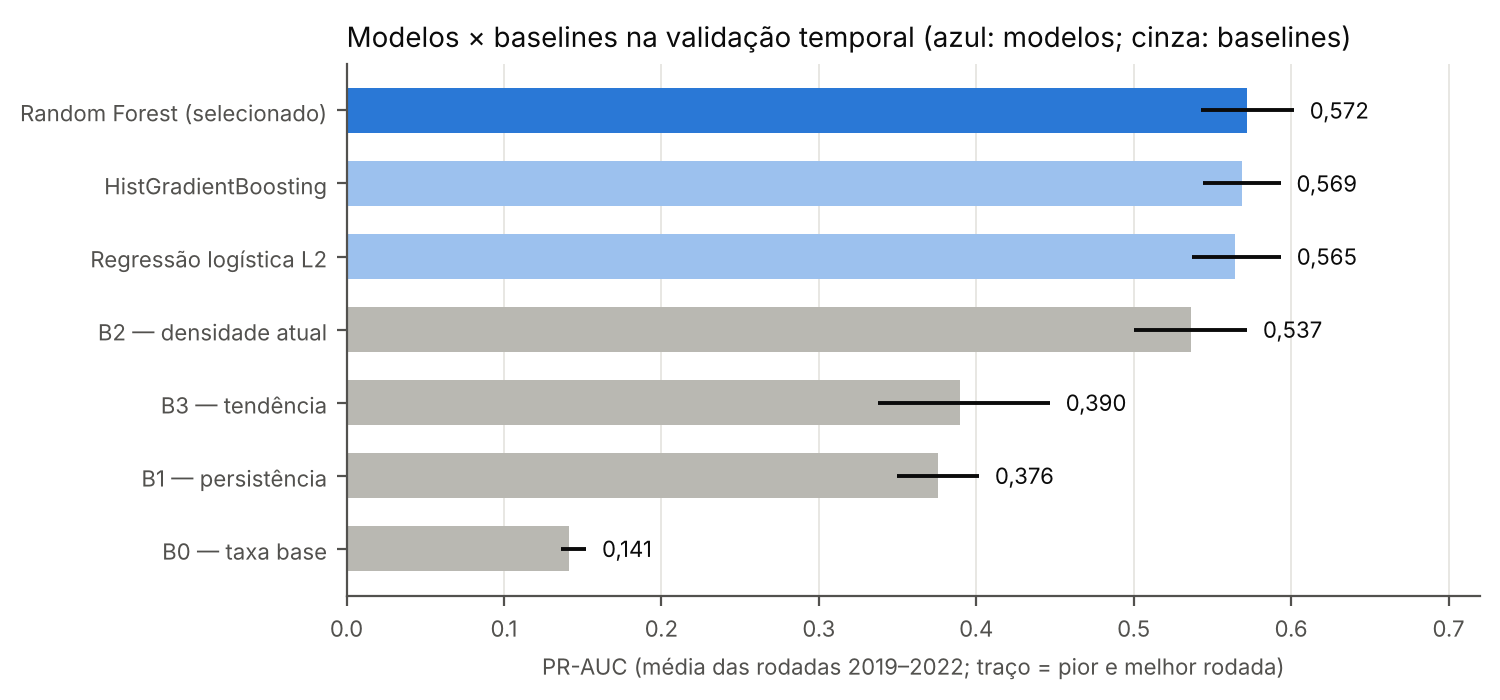

In [6]:
selecao = pd.read_csv(TREINO / "selecao_configuracoes.csv")
selecao_coorte = pd.read_csv(TREINO / "selecao_metricas_por_coorte.csv")
val = pd.read_csv(TREINO / "metricas_validacao_por_coorte.csv")
protocolo = TR.ler_protocolo(PV.CAMINHO_PROTOCOLO)          # falha se o arquivo tiver sido alterado
print("Protocolo congelado:", protocolo["algoritmo"], protocolo["hiperparametros"],
      "| features:", len(protocolo["features"]), "| SHA-256:", protocolo["sha256_protocolo"][:12])
if RODAR_SELECAO_COMPLETA:
    _, refeita = TR.selecionar(P[P.origem != TR.ORIGEM_TESTE])
    assert (refeita.iloc[0].metodo, json.loads(refeita.iloc[0].config)) == (protocolo["algoritmo"], protocolo["hiperparametros"])
    print("Seleção refeita: mesmo vencedor do protocolo.")

fig = AP.grafico_desempenho(selecao, selecao_coorte, val)
salvar(fig, "desempenho_modelos_baselines.png")
plt.show()

**Leitura**
- **Os três algoritmos ficam no mesmo patamar:** PR-AUC média de 0,565 a 0,572. A escolha do algoritmo pesa pouco.
- **B0, B1 e B3 ficam bem abaixo** dos modelos.
- **B2, a densidade atual, fica perto:** 0,537 de média. Quase toda a informação útil está no nível atual de acesso.

## 7. Avaliação dos resultados e análise de calibração
### 7.1 Validação temporal e teste reservado
O teste de 2023 vem do arquivo salvo; ele não é refeito. O intervalo de confiança de 95% da diferença entre RF e B2 é calculado por reamostragem dos municípios.

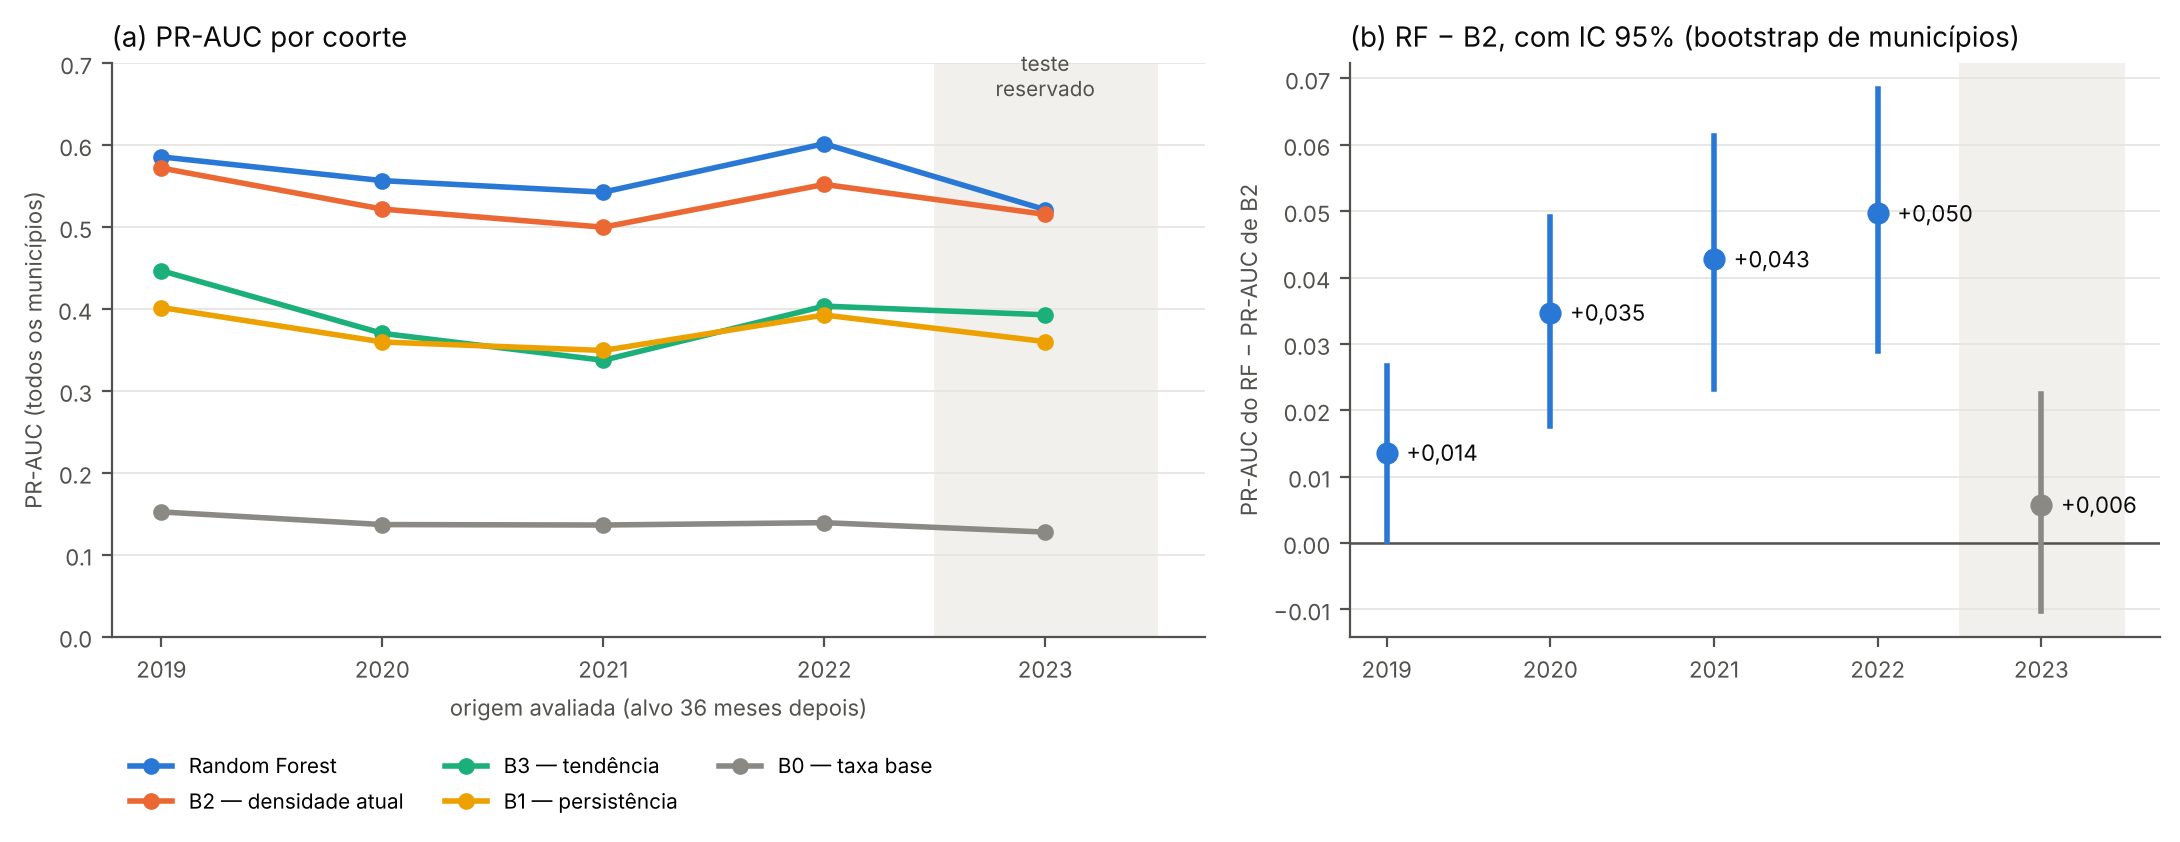

pr_auc                                 recall_top25                                
origem             2019-02 2020-02 2021-02 2022-02 2023-02      2019-02 2020-02 2021-02 2022-02 2023-02
metodo                                                                                                 
B2_densidade_atual   0.572   0.522   0.500   0.552   0.516        0.777   0.776   0.763   0.812   0.812
random_forest        0.586   0.557   0.543   0.602   0.521        0.784   0.780   0.783   0.825   0.826

In [7]:
teste = pd.read_csv(TREINO / "teste_2023_metricas.csv", dtype={"regra": str, "sensibilidade": str})
teste = teste[(teste.regra == "atual") & (teste.sensibilidade == "principal")]
dif = pd.concat([pd.read_csv(TREINO / "comparacao_modelo_vs_B2_validacao.csv"),
                 pd.read_csv(TREINO / "comparacao_modelo_vs_B2_teste.csv")])
fig = AP.grafico_validacao_teste(val, teste, dif)
salvar(fig, "validacao_e_teste.png")
plt.show()

t = pd.concat([val, teste])
t = t[(t.grupo == "todos") & t.metodo.isin(["random_forest", "B2_densidade_atual"])]
t.pivot_table(index="metodo", columns="origem", values=["pr_auc", "recall_top25"]).round(3)

**Leitura**
- **Validação:** o RF supera B2 nas quatro rodadas, por uma margem pequena (+0,014 a +0,050).
- **Teste reservado (2023):** a diferença cai para **+0,006**, com IC de −0,010 a +0,023. **Não se distingue de zero.**
- **Municípios ainda acima do P25:** é onde a previsão seria mais útil, mas a vantagem não é consistente.
- **Conclusão:** o Random Forest **não demonstrou vantagem robusta** sobre a ordenação pela densidade atual.

### 7.2 Calibração: o escore pode ser lido como probabilidade?
A análise é pequena e temporalmente correta. Ela **só usa as rodadas de validação** para decidir, e o critério foi **fixado no código antes do cálculo** (`PV.CRITERIOS_DIVULGACAO`):
- erro médio de no máximo 0,02;
- inclinação de calibração entre 0,80 e 1,25;
- erro no decil de maior risco de no máximo 0,05;
- Brier não pior que o de uma referência simples.

Tudo isso precisa valer **nas 4 rodadas**.

**Versões comparadas**
- **RF bruto:** o escore do protocolo congelado.
- **RF + Platt:** calibração sigmoide ajustada numa coorte anterior, sem ver a coorte avaliada.
- **B2p:** regressão logística só com a densidade atual.

A coorte de 2023 aparece **separada, como pós-teste**: é só descritiva e não é uma validação independente.

,rodada,uso,versao,prevalencia,prob_media,inclinacao,decil_sup_prob,decil_sup_obs,brier
0,validacao_2019-02,validacao,rf_bruto,0.152,0.124,0.760,0.656,0.627,0.090
2,validacao_2019-02,validacao,rf_platt,0.152,0.108,0.696,0.620,0.627,0.092
4,validacao_2019-02,validacao,B2p_densidade,0.152,0.121,0.523,0.739,0.614,0.094
6,validacao_2020-02,validacao,rf_bruto,0.137,0.107,0.786,0.601,0.600,0.084
8,validacao_2020-02,validacao,rf_platt,0.137,0.103,0.819,0.574,0.600,0.084
10,validacao_2020-02,validacao,B2p_densidade,0.137,0.106,0.518,0.693,0.557,0.090
12,validacao_2021-02,validacao,rf_bruto,0.136,0.099,0.865,0.535,0.580,0.086
14,validacao_2021-02,validacao,rf_platt,0.136,0.125,1.035,0.563,0.580,0.083
16,validacao_2021-02,validacao,B2p_densidade,0.136,0.099,0.516,0.666,0.558,0.092
18,validacao_2022-02,validacao,rf_bruto,0.139,0.088,1.065,0.470,0.639,0.085


,versao,calibracao_geral,inclinacao,decil_superior,brier_vs_B2p,aprovada
0,rf_bruto,0/4,2/4,3/4,4/4,False
1,rf_platt,1/4,3/4,3/4,4/4,False


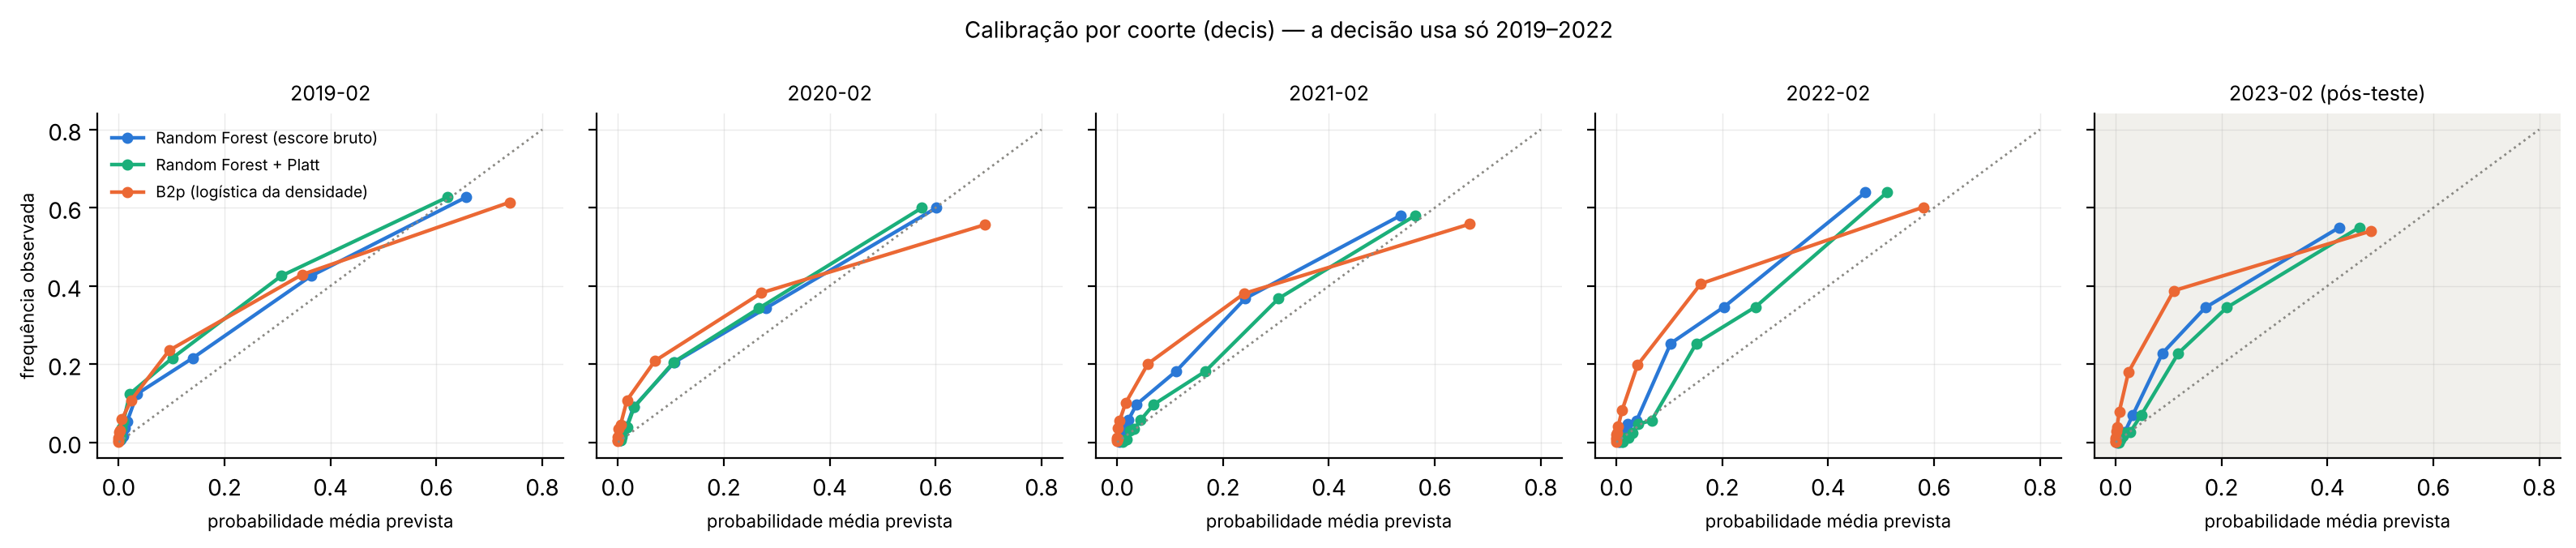

In [8]:
calibracao, decisao, curvas = PV.analise_calibracao(P)
rf_val = val[(val.grupo == "todos") & (val.metodo == protocolo["algoritmo"])].set_index("rodada").pr_auc
rf_agora = calibracao.query("grupo == 'todos' and versao == 'rf_bruto' and uso == 'validacao'").set_index("rodada").pr_auc
assert (rf_agora.reindex(rf_val.index) - rf_val).abs().max() < 1e-12      # mesmos resultados da validação aprovada

cols = ["rodada", "uso", "versao", "prevalencia", "prob_media", "inclinacao", "decil_sup_prob", "decil_sup_obs", "brier"]
display(calibracao[calibracao.grupo == "todos"][cols].round(3))
display(decisao)
PV.grafico_calibracao(curvas)
plt.show()

**Leitura**
- **Brier:** o RF tem Brier 5% a 7% menor que o da referência B2p em todas as rodadas. Ele acrescenta alguma informação probabilística.
- **Subestimação crescente:** o RF subestima o risco médio, e cada vez mais. A razão entre previsto e observado cai de 0,82 em 2019 para 0,63 em 2022.
- **Faixa de maior risco:** em 2022, o RF prevê 0,47 e o observado é 0,64.
- **Platt:** a calibração não fica estável. Ela melhora em 2021 e 2022 e piora em 2019.
- **Decisão pela regra pré-registrada:** **nenhuma versão é aprovada**. As probabilidades **não foram homologadas como calibradas**. O escore do RF é tratado como **valor técnico de ordenação**, e a comunicação usa **ranking e categorias relativas**.
- **Limite da evidência:** quatro rodadas, com os mesmos municípios repetidos, não bastam para mostrar que um calibrador se mantém estável três anos à frente.

## 8. Previsão e priorização dos municípios para fevereiro de 2029
### 8.1 Verificação do protocolo antes de prever
A previsão **é interrompida** se qualquer verificação falhar.

In [9]:
verificacao = PV.verificar_protocolo(P, P26)
display(verificacao)
assert verificacao.ok.all(), "verificação do protocolo falhou: previsão interrompida"
assert not decisao.aprovada.any(), "critério aprovado: a probabilidade calibrada precisaria entrar na previsão"

,verificacao,ok,detalhe
0,Protocolo íntegro (assinatura do conteúdo),True,5506786ef9c5
1,"Features = FEATURES_MODELO_PRINCIPAL (30, só A...",True,30
2,Algoritmo e hiperparâmetros congelados,True,"{""max_features"": ""sqrt"", ""min_samples_leaf"": 300}"
3,Pré-processamento: imputação pela mediana do t...,True,imputacao → modelo
4,Horizonte de 36 meses,True,2029-02
5,Origem 2026-02 sem alvo observado,True,alvo vazio
6,Nenhuma informação posterior à origem (grade t...,True,2026-02
7,Censo fora das features,True,0 variáveis
8,10 coortes 2014–2023 elegíveis (alvo de treino...,True,10 coortes. 55.686 pares
9,Todos os municípios com features na origem 202...,True,5570


### 8.2 Treino operacional e base final
O procedimento congelado é treinado nas 10 coortes de 2014 a 2023 e aplicado às features de fevereiro de 2026.

**Para cada município**
- duas ordenações: **posição no RF** (1 = maior escore) e **posição em B2** (1 = menor densidade);
- categorias relativas para cada método: **maior** (25% primeiros), **intermediário** (25% a 50%) e **menor** (demais).

**Classificação de prioridade:** cruzamento das categorias dos dois métodos, **sem pesos**.
- **alta, consenso:** top 25% nos dois;
- **alta, divergente:** top 25% em só um; precisa de revisão;
- **intermediária;**
- **menor.**

A base recalculada e as demais tabelas da previsão são **comparadas byte a byte** com os arquivos aprovados em `etapa2/saidas/previsao2029/`, sem regravá-los.

In [10]:
modelo, treino_op = PV.treinar_operacional(P)
print(f"Treino operacional: {len(treino_op):,} pares de {treino_op.origem.nunique()} coortes "
      f"({treino_op.origem.min()} a {treino_op.origem.max()})".replace(",", "."))
base = PV.previsao_final(modelo, P26, P, dados["ibge"])

# demais tabelas da previsão (comparação, confiabilidade e estabilidade), recalculadas para a conferência
comparacao = PV.comparar_rankings(base)
divergencias = base[base.concordancia_top25.isin(["so_rf", "so_b2"])].sort_values(["concordancia_top25", "posicao_rf"])
qualidade = PV.qualidade_entradas(base, P26, P, protocolo["features"])
drift = PV.drift_2026(P, P26)
escore_medio = PV.escore_medio(calibracao, base)
modelo_l6, _ = PV.treinar_operacional(P, TR.features_L6())                  # sensibilidade L=6 (fora do resultado principal)
estabilidade = PV.estabilidade(base, PV.prever_2029(modelo_l6, P26, dados["ibge"], TR.features_L6()))
r = dict(previsao=base, comparacao=comparacao, estabilidade=estabilidade, qualidade=qualidade, drift=drift,
         divergencias=divergencias, verificacao=verificacao, calibracao=calibracao, decisao=decisao, curvas=curvas,
         escore_medio=escore_medio, hist=P, p26=P26)
conferencia = PV.conferir_ou_salvar(r)
display(conferencia)
assert not conferencia.situacao.str.startswith("DIFERENTE").any(), "a previsão recalculada difere da aprovada"

base.head(10)[["id_municipio", "municipio", "sigla_uf", "densidade_fev2026", "tendencia_36", "posicao_rf", "posicao_b2",
               "classificacao_prioridade"]].round(2)

Treino operacional: 55.686 pares de 10 coortes (2014-02 a 2023-02)


,arquivo,situacao
0,previsoes_2029_municipios.csv,idêntico ao aprovado
1,comparacao_rf_b2_2029.csv,idêntico ao aprovado
2,divergencias_rf_b2_2029.csv,idêntico ao aprovado
3,verificacao_protocolo.csv,idêntico ao aprovado
4,calibracao_por_coorte.csv,idêntico ao aprovado
5,decisao_divulgacao_probabilidades.csv,idêntico ao aprovado
6,confiabilidade_entradas_2026.csv,idêntico ao aprovado


,id_municipio,municipio,sigla_uf,densidade_fev2026,tendencia_36,posicao_rf,posicao_b2,classificacao_prioridade
0,2708204,São Brás,AL,0.21,-0.02,1,6,alta_consenso
1,2503605,Caiçara,PB,0.36,-0.02,2,31,alta_consenso
2,2105658,Junco do Maranhão,MA,0.68,0.08,3,82,alta_consenso
3,2920304,Malhada de Pedras,BA,0.43,0.02,4,40,alta_consenso
4,3150539,Pingo-d'Água,MG,0.35,-0.10,5,29,alta_consenso
5,2903276,Barrocas,BA,0.17,0.01,6,2,alta_consenso
6,2922755,Nova Ibiá,BA,0.37,-0.14,7,34,alta_consenso
7,1505494,Palestina do Pará,PA,0.48,0.09,8,48,alta_consenso
8,2500205,Aguiar,PB,0.53,-0.09,9,58,alta_consenso
9,2703205,Igreja Nova,AL,0.25,-0.20,10,9,alta_consenso


**Como ler**
- **Escore:** a coluna `escore_rf` é um **valor técnico de ordenação, não calibrado**. Não deve ser lida como chance ou porcentagem.
- **Relatividade:** posições e categorias valem **em relação aos 5.570 municípios** em fevereiro de 2026.
- **O que não há na base:** nenhuma densidade de 2029 foi estimada, e nenhuma classificação é resultado observado.

### 8.3 Distribuição das categorias de prioridade
Os **alertas de qualidade** são uma camada **separada**: não alteram a categoria de prioridade e aparecem num painel próprio. Um alerta indica pelo menos uma destas condições:
- flag causal aberta;
- mês ausente;
- suspeita estatística em 36 meses;
- histórico curto;
- três ou mais features fora da faixa do treino.

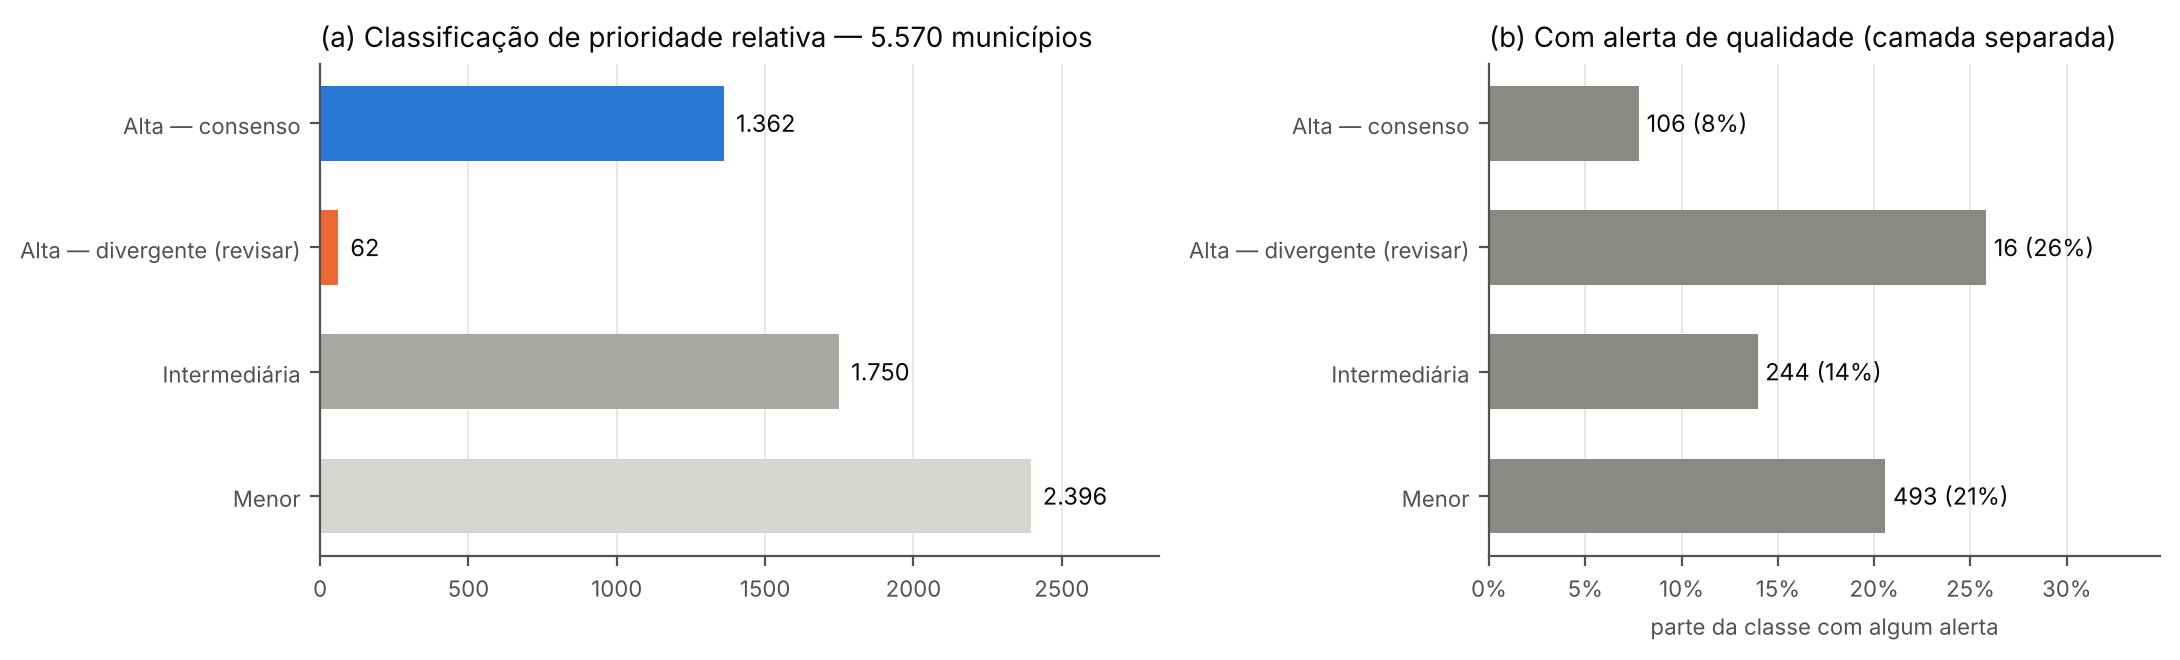

In [11]:
fig = AP.grafico_prioridade(base)
salvar(fig, "prioridade_e_alertas_2029.png")
plt.show()

### 8.4 Comparação entre Random Forest e B2

,medida,valor
0,Municípios no top 25% (RF),1393
1,Municípios no top 25% (B2),1393
2,Selecionados por ambos,1362
3,Só pelo Random Forest,31
4,Só pelo B2,31
5,Concordância do top 25%,97.8%
6,Correlação de Spearman entre as posições,0.842
7,Mediana de |diferença de posições| no top 25% ...,125


Features mais importantes do RF operacional (importância por impureza): abaixo_p25_na_origem 0,19, densidade_atual 0,15, media_12 0,13, mediana_12 0,10


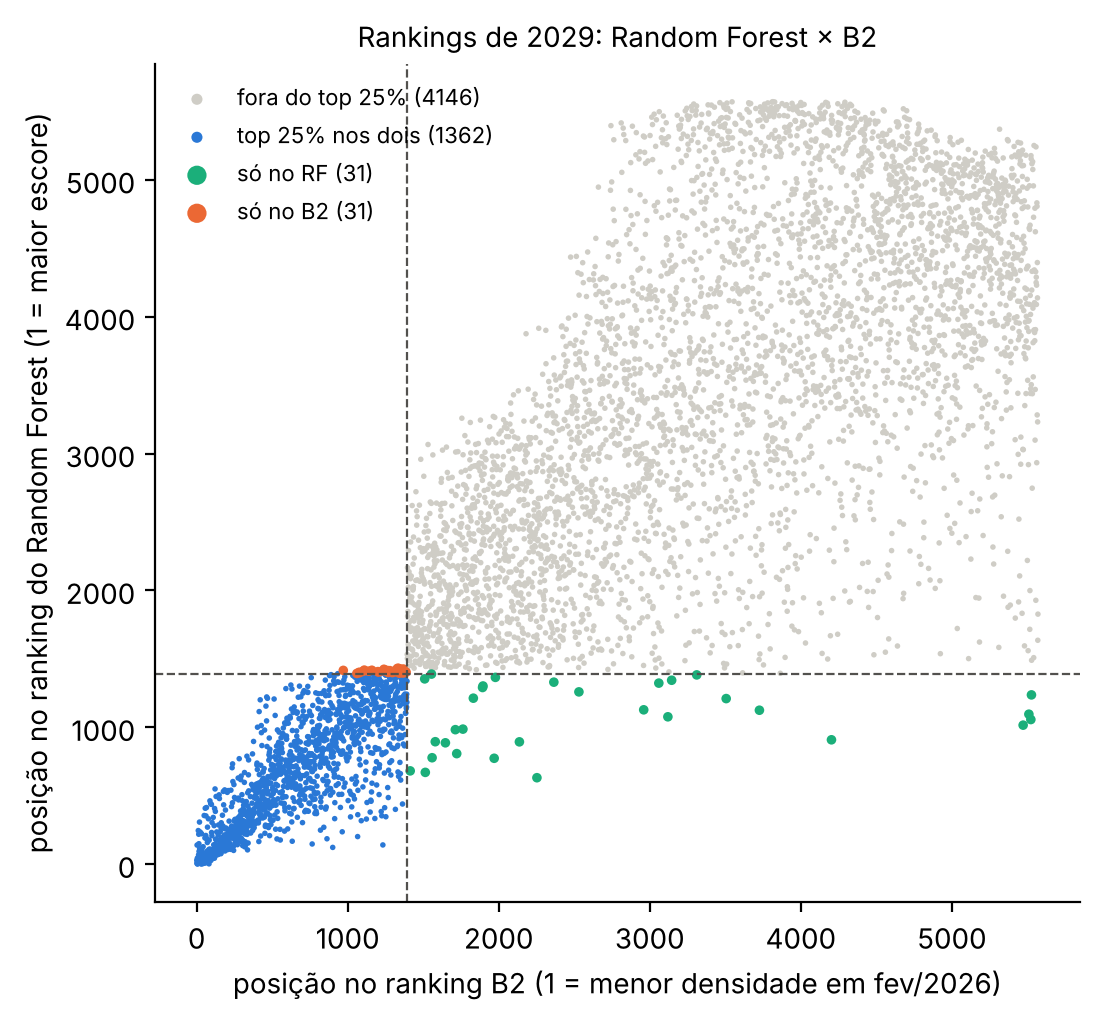

,concordancia_top25,municipio,sigla_uf,densidade_fev2026,densidade_lag_36,tendencia_36,suspeitas_36m,posicao_rf,posicao_b2,alerta_qualidade
1056,so_rf,Itati,RS,54.40,1.06,14.54,9,1057,5523,True
1015,so_rf,Morrinhos do Sul,RS,46.27,1.11,12.31,9,1016,5472,True
1095,so_rf,Três Forquilhas,RS,51.99,1.49,12.81,8,1096,5510,True
1236,so_rf,Mampituba,RS,55.05,3.03,12.47,8,1237,5527,True
1415,so_b2,Bela Cruz,CE,6.01,5.64,3.49,0,1416,971,False
1393,so_b2,Jardim,MS,6.52,8.14,3.17,4,1394,1061,True
1401,so_b2,Brejetuba,ES,6.58,9.87,1.63,0,1402,1076,False
1398,so_b2,Mato Grosso,PB,6.60,6.21,1.96,0,1399,1078,False


In [12]:
display(comparacao)
imp = pd.Series(modelo.named_steps["modelo"].feature_importances_,
                index=modelo.named_steps["imputacao"].get_feature_names_out()).sort_values(ascending=False)
print("Features mais importantes do RF operacional (importância por impureza):",
      ", ".join(f"{k} {v:.2f}".replace(".", ",") for k, v in imp.head(4).items()))
PV.grafico_rankings(base)
plt.show()

exemplos = (divergencias.assign(dist=divergencias.diferenca_posicoes.abs())
            .sort_values("dist", ascending=False).groupby("concordancia_top25").head(4))
exemplos.join(P26.set_index("id_municipio")[["densidade_lag_36"]], on="id_municipio")[
    ["concordancia_top25", "municipio", "sigla_uf", "densidade_fev2026", "densidade_lag_36", "tendencia_36",
     "suspeitas_36m", "posicao_rf", "posicao_b2", "alerta_qualidade"]].round(2)

**Leitura**
- **Os dois tops quase coincidem:** o top 25% de B2 são exatamente os 1.393 municípios já abaixo de 8,20 em fevereiro de 2026, e o RF concorda em **97,8%** deles.
- **Onde há divergência (62 municípios):** em séries com **mudança brusca recente**.
  - **Só no RF:** municípios que saltaram de cerca de 1 acesso para mais de 20, alguns para cerca de 50. Muitos têm suspeitas estatísticas; metade tem alerta de qualidade.
  - **Só no B2:** municípios logo abaixo do limiar que caíram recentemente.
- **Concordância não confirma o risco.** Os dois métodos dependem da **mesma informação observada**: a densidade atual. Ela é a ordenação de B2 e está entre as features mais importantes do RF, junto com o indicador "abaixo do P25 na origem". Concordar mostra que a priorização não depende da escolha do método. **Não é uma confirmação independente de que o município estará abaixo do limiar em 2029.**
- **Diferença não prova superioridade:** no teste, a vantagem do RF não se distinguiu de zero.

**Recomendação de uso, sem ranking combinado**
1. **Lista principal:** o grupo **alta, consenso** (1.362).
2. **Revisão manual:** os **62 divergentes**, conferindo a série com a Anatel.
3. **Se for preciso um único ranking:** **B2**. O desempenho é equivalente, e ele é mais simples e transparente. O RF fica como resultado do modelo e sinal complementar.

### 8.5 Distribuição regional dos municípios prioritários

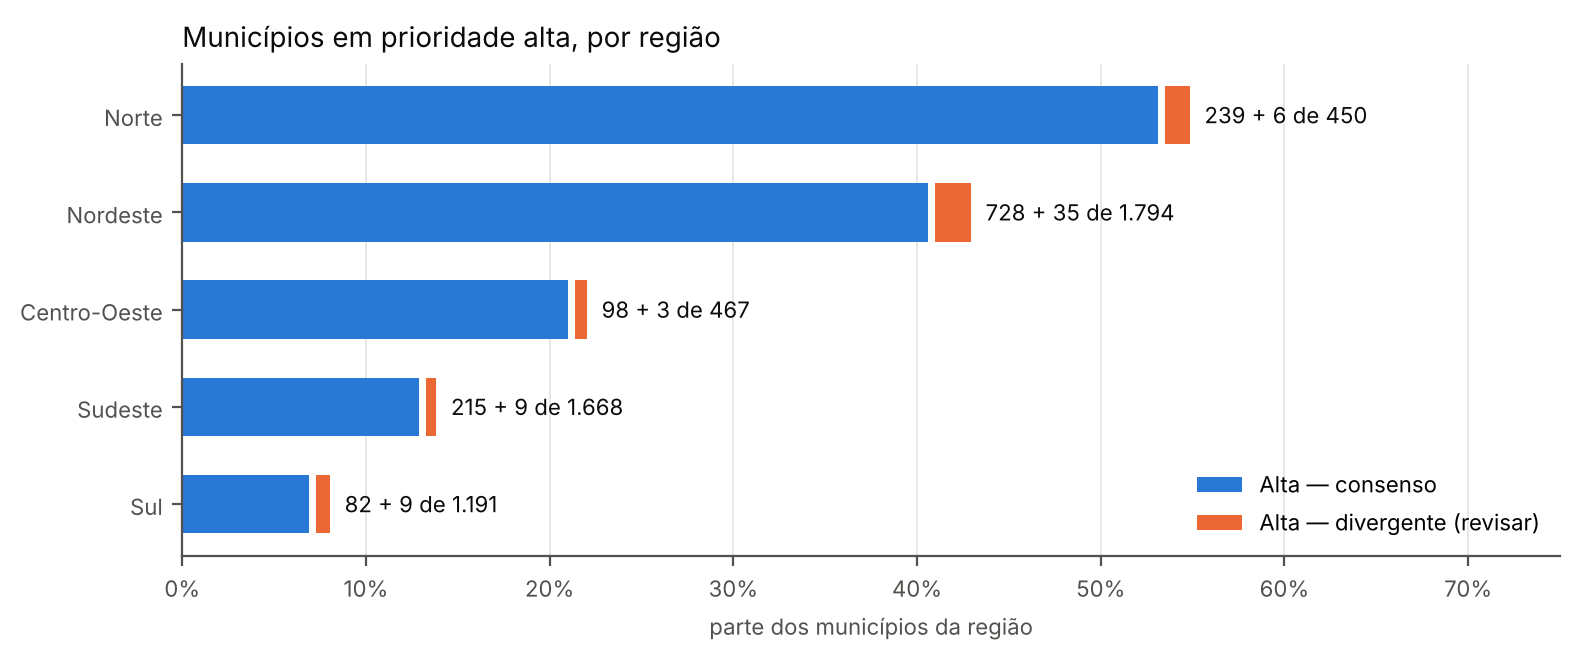

classificacao_prioridade,municipios,alta_consenso,alta_divergente_revisar,pct_alta_consenso,participacao_no_consenso
regiao,,,,,
Norte,450,239,6,0.531,0.175
Nordeste,1794,728,35,0.406,0.535
Centro-Oeste,467,98,3,0.210,0.072
Sudeste,1668,215,9,0.129,0.158
Sul,1191,82,9,0.069,0.060


In [13]:
fig = AP.grafico_regional(base)
salvar(fig, "prioridade_por_regiao_2029.png")
plt.show()
reg = AP.resumo_regional(base)
reg[["municipios", "alta_consenso", "alta_divergente_revisar", "pct_alta_consenso", "participacao_no_consenso"]].round(3)

**Leitura**
- **Concentração:** Nordeste (728) e Norte (239) somam **71%** do grupo de consenso.
- **Em proporção:** entram 53% dos municípios do Norte e 41% dos do Nordeste, contra 13% do Sudeste e 7% do Sul.
- **Uso:** a distribuição descreve onde está a baixa densidade **observada hoje** e o risco relativo estimado; não é uma projeção do número de municípios em 2029.

### 8.6 Confiabilidade da previsão
Esta seção cobre:
- qualidade das entradas;
- mudança de distribuição entre as origens de treino e 2026;
- escore médio;
- estabilidade com as sinalizações L=6 no lugar de L=12.

,indicador,municipios,no_top25_rf
0,Feature ausente (exceto a estrutural 'meses de...,0,0
1,Sem sinalização anterior (feature estrutural v...,4926,1243
2,Mês ausente nos últimos 36 meses,0,0
3,Sinalização causal aberta em fev/2026 (flag ≠ 0),55,28
4,Suspeita estatística nos últimos 36 meses,300,94
5,Histórico menor que 36 meses,0,0
6,Idade da série acima do máximo do treino (efei...,5541,1379
7,"Densidade acima do p99,5 do treino (valor extr...",263,4
8,Alguma feature não estrutural fora da faixa p0...,1111,169
9,Três ou mais features fora dessa faixa (condiç...,677,73


,feature,mediana_2014,mediana_2023,mediana_2026,p90_treino,p90_2026,max_treino,acima_max_treino_2026,fora_p1_p99_treino_2026
0,densidade_atual,2.690,11.956,17.133,19.077,35.755,991.462,0.000,0.105
1,tendencia_36,0.425,1.495,1.166,2.841,4.191,117.197,0.000,0.044
2,volatilidade_12,0.020,0.090,0.079,0.291,0.384,2.388,0.000,0.025
3,n_meses_ausentes_36,0.000,0.000,0.000,0.000,0.000,21.000,0.000,0.000
4,n_suspeita_36,0.000,0.000,0.000,0.000,0.000,29.000,0.000,0.022
5,flag_causal_atual,0.000,0.000,0.000,0.000,0.000,2.000,0.000,0.010
6,meses_desde_primeira_obs,83.000,191.000,227.000,179.000,227.000,191.000,0.995,0.995


,rodada,uso,prevalencia,prob_media
0,validacao_2019-02,validacao,0.152,0.124
1,validacao_2020-02,validacao,0.137,0.107
2,validacao_2021-02,validacao,0.136,0.099
3,validacao_2022-02,validacao,0.139,0.088
4,teste_2023-02,pos_teste,0.128,0.076
5,previsao_2026-02,operacional,NaN,0.062


,comparacao,top25_comum,entram_ou_saem,spearman,max_dif_escore
0,RF principal (L=12) × RF sensibilidade (L=6),0.988,17,0.996,0.025
1,RF principal (L=12) × B2 (densidade atual),0.978,31,0.842,NaN


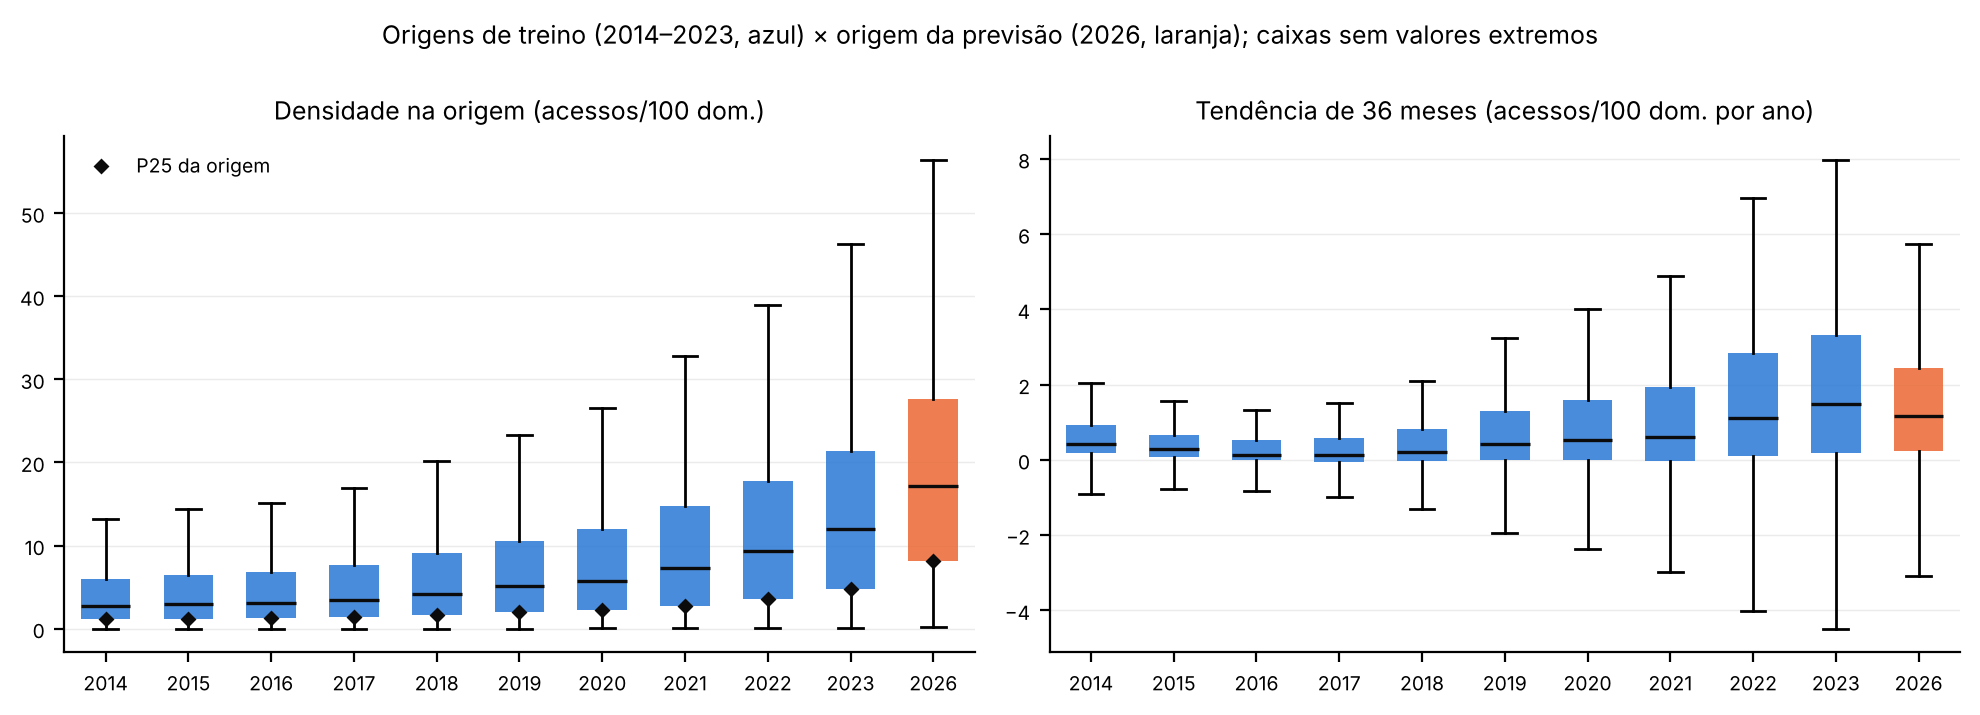

In [14]:
display(qualidade, drift.round(3), escore_medio.round(3), estabilidade.round(3))
PV.grafico_drift(P, P26)
plt.show()

**Leitura**
- **Entradas.** Não há meses ausentes recentes nem históricos curtos.
  - 55 municípios têm flag causal aberta, e 300 têm suspeita estatística em 36 meses.
  - **859** municípios têm algum alerta de qualidade, 122 deles nas classes de prioridade alta.
- **Mudança de distribuição.**
  - A densidade mediana é 17,1 em 2026, contra 12,0 em 2023 e 2,7 em 2014; 10,5% dos municípios estão fora da faixa p1–p99 do treino.
  - **O nível absoluto de 2026 está fora do histórico**, e o RF usa densidades absolutas. Por isso, **a extrapolação para 2029 tem confiabilidade limitada**.
- **Escore médio.** É 0,062 em 2026, contra prevalências históricas de 13% a 21%. Isso reforça que o escore não é uma probabilidade.
- **Estabilidade.** Com L=6, o top 25% muda em 17 municípios (98,8% em comum). A priorização não depende desse parâmetro.

### 8.7 Base final para o dashboard
**Arquivo:** `etapa2/saidas/previsao2029/previsoes_2029_municipios.csv`, com uma linha por município e codificação UTF-8. Cada linha traz:
- identificação e UF;
- densidade observada em fevereiro de 2026;
- rankings RF e B2;
- classificação de prioridade;
- indicadores de qualidade;
- escore técnico **não calibrado**.

**Dicionário:** `dicionario_previsoes_2029.csv`, na mesma pasta.

**Leitura recomendada:** `id_municipio` como texto. A região pode ser derivada do primeiro dígito do código IBGE.

In [15]:
dicionario = AP.dicionario_base_2029()
with open(PREVISAO / "dicionario_previsoes_2029.csv", "w", encoding="utf-8", newline="") as f:
    f.write(PV.texto_csv(dicionario))
base_csv = AP.ler_base_2029(PREVISAO / "previsoes_2029_municipios.csv")      # como o dashboard vai ler
validacao = AP.validar_base_dashboard(base_csv)
display(validacao)
assert validacao.ok.all()
dicionario[["coluna", "grupo", "descricao", "valores_unidade"]]

,verificacao,ok
0,"5.570 municípios, um por linha",True
1,Colunas = dicionário (mesma ordem),True
2,Sem valores ausentes,True
3,Código IBGE com 7 dígitos e região derivável,True
4,27 UFs,True
5,Rankings sem empates (1 a 5.570),True
6,Categorias válidas e com 25% / 25% / 50%,True
7,Prioridade só com os 4 valores previstos,True
8,Escore técnico entre 0 e 1,True
9,Nenhuma coluna de probabilidade ou densidade f...,True


,coluna,grupo,descricao,valores_unidade
0,id_municipio,identificação,Código IBGE do município,ler como texto
1,municipio,identificação,"Nome do município (IBGE, Censo 2022)",
2,sigla_uf,identificação,Sigla da UF,27 UFs
3,densidade_fev2026,situação observada,Densidade de banda larga fixa publicada pela A...,acessos por 100 domicílios
4,limiar_p25_origem,situação observada,"P25 nacional da densidade em fev/2026, congela...","8,20 para todos"
5,abaixo_limiar_em_fev2026,situação observada,O município já está abaixo do limiar em fev/20...,True / False
6,escore_rf,técnico — NÃO CALIBRADO — não é probabilidade,Escore do Random Forest para estar abaixo do l...,"0 a 1, sem unidade"
7,posicao_rf,ranking e prioridade,Posição no ranking do Random Forest (1 = maior...,"1 a 5.570, sem empates"
8,posicao_b2,ranking e prioridade,Posição no ranking B2 (1 = menor densidade em ...,"1 a 5.570, sem empates (desempate pelo código ..."
9,diferenca_posicoes,ranking e prioridade,posicao_b2 − posicao_rf,> 0: o RF coloca o município mais à frente que...


## 9. Conclusões e limitações
### Conclusões
1. **Resultado.** Os 5.570 municípios foram ordenados pelo **risco relativo** de estarem abaixo de 8,20 acessos por 100 domicílios em **fevereiro de 2029**, a partir dos dados de fevereiro de 2026.
   - **1.362** municípios estão em **prioridade alta por consenso**, e **62** são **divergentes**, para revisão.
   - O grupo de consenso concentra-se no Nordeste e no Norte e tem densidade mediana de 4,6.
2. **Modelo × referência simples.** O Random Forest tem desempenho bem acima dos baselines ingênuos.
   - **Não demonstrou vantagem robusta** sobre a densidade atual (B2): no teste, a diferença foi de +0,006, com intervalo que inclui zero.
   - As duas listas prioritárias coincidem em 97,8%.
3. **Probabilidades.** **Não foram homologadas como calibradas.** Os escores ficam como valores técnicos, e a comunicação usa ranking e categorias relativas.
4. **Atenção prioritária.** Merecem mais atenção os municípios do grupo de consenso com densidade muito baixa e sem crescimento: 266 abaixo de 2 acessos e 445 com tendência nula ou negativa.
5. **Concordância ≠ confirmação.** A concordância entre RF e B2 mostra que a lista não depende do método. Ela **não confirma de forma independente** o risco futuro, porque os dois se apoiam na densidade atual.

### Limitações
- **Poucas coortes independentes:** 10 origens com os mesmos municípios repetidos, rodadas dependentes e um teste de um único ano, já consultado.
- **Mudança estrutural:** o nível de densidade de 2026 está fora do histórico. Mudanças entre 2026 e 2029 em tecnologia, políticas ou coleta da Anatel podem alterar as relações aprendidas.
- **Disponibilidade dos dados:** supõe-se que os dados da Anatel da competência estão disponíveis na origem.
- **Qualidade dos dados:** as sinalizações são suspeitas estatísticas, não erros comprovados. As divergências entre RF e B2 se concentram em séries com alerta, que ficam separadas da prioridade.
- **Calibração:** não demonstrada; houve subestimação crescente no período avaliado.
- **Natureza do resultado:** a previsão é uma **priorização relativa**, **não um resultado futuro observado** nem uma garantia.

### Situação da entrega
A base de 2029 está pronta para a etapa de visualização, com dicionário e verificações de uso direto. Gráficos deste notebook: `etapa2/saidas/figuras/`.

### Verificações finais
Rodam os testes automáticos do projeto, e só a linha de resumo é mostrada. Em seguida, confere-se que nenhum arquivo aprovado foi alterado durante a execução.

In [16]:
t = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", "tests"],
                   capture_output=True, text=True)
print(t.stdout.strip().splitlines()[-1])
assert t.returncode == 0
alterados = [p for p in PROTEGIDOS if sha(p) != hash_inicio[str(p)]]
assert not alterados, alterados
print(f"{len(PROTEGIDOS)} arquivos aprovados conferidos: nenhum alterado.")

36 passed in 69.37s (0:01:09)


42 arquivos aprovados conferidos: nenhum alterado.
